# Analysis

Python is the default kernel. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The quantity and the stake are the ones in `PROPOSAL.md` and the 2026-10-29 entry in `decisions.md`. The held-out score, in stake units per match, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

The packages are pinned in `requirements.txt` for the interpreter in `.python-version`. The split is a cutoff date and the fit starts from a fixed point, so the held-out scores do not depend on a seed. The simulation check draws from seed 20241118, recorded in `decisions.md`. Before the fit, each file in `data/` is checked against the SHA-256 in `data/README.md`.


In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import poisson

try:
    display
except NameError:
    def display(obj):
        print(obj)

DATA_DIR = Path("data")
FIG_DIR = Path("fig")
FIG_DIR.mkdir(exist_ok=True)

# Season code in the Football-Data URL, then the season label.
SEASONS = [
    ("1920", "2019/20"),
    ("2021", "2020/21"),
    ("2122", "2021/22"),
    ("2223", "2022/23"),
    ("2324", "2023/24"),
    ("2425", "2024/25"),
]
CUTOFF = pd.Timestamp("2024-05-19")

readme = (DATA_DIR / "README.md").read_text()
listed = dict(re.findall(r"(E0_\d{4}\.csv)\s*\|\s*([0-9a-f]{64})", readme))
expected_names = {f"E0_{code}.csv" for code, _ in SEASONS}
if set(listed) != expected_names:
    raise RuntimeError(
        "data/README.md should list the six E0 files and no others. "
        f"Found {sorted(listed)}."
    )

def sha256(path):
    digest = hashlib.sha256()
    digest.update(path.read_bytes())
    return digest.hexdigest()

for name, expected in sorted(listed.items()):
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(
            f"{path} is missing. Download it with the command in data/README.md."
        )
    got = sha256(path)
    if got != expected:
        raise RuntimeError(f"{name} SHA-256 is {got}. data/README.md has {expected}.")

frames = []
for code, label in SEASONS:
    frame = pd.read_csv(
        DATA_DIR / f"E0_{code}.csv",
        usecols=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "B365C>2.5", "B365C<2.5"],
    )
    frame.insert(0, "season", label)
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True)
raw["date"] = pd.to_datetime(raw["Date"], dayfirst=True)
raw["home_goals"] = raw["FTHG"].astype(int)
raw["away_goals"] = raw["FTAG"].astype(int)
raw["total_goals"] = raw["home_goals"] + raw["away_goals"]
raw["over"] = raw["total_goals"] > 2.5
raw["o_over"] = raw["B365C>2.5"].astype(float)
raw["o_under"] = raw["B365C<2.5"].astype(float)

usable = (raw["o_over"] > 1.0) & (raw["o_under"] > 1.0)
dropped = raw.loc[~usable, ["date", "season", "HomeTeam", "AwayTeam", "home_goals", "away_goals", "o_over", "o_under"]].copy()
matches = raw.loc[usable].reset_index(drop=True)

if len(raw) != 2280 or len(dropped) != 1 or len(matches) != 2279:
    raise RuntimeError(
        f"Expected 2280 rows, 1 dropped, 2279 kept. Got {len(raw)}, {len(dropped)}, {len(matches)}."
    )

row = dropped.iloc[0]
print(f"Checked 6 files. Read {len(raw)} matches. Kept {len(matches)}.")
print(
    f"Dropped {row.HomeTeam} v {row.AwayTeam} on {row.date:%d %B %Y} "
    f"({row.season}): closing prices {row.o_over:g} and {row.o_under:g}."
)


Checked 6 files. Read 2280 matches. Kept 2279.
Dropped Newcastle v Man City on 19 December 2021 (2021/22): closing prices 0 and 0.


## Question

A probability built only from information available before the close is used to decide a one-unit stake on the Premier League total.

The quantity is \(P(Q > 2.5)\), the probability that one match's full-time total exceeds 2.5 goals. \(Q\) is home goals plus away goals. The probability is scored on each match from 16 August 2024 through 25 May 2025. Matches used to build the forecast run from 9 August 2019 through 19 May 2024.

The decision is the 2026-10-29 rule. Stake one unit on the over when \(p > 1/o_{\text{over}}\), one unit on the under when \(1 - p > 1/o_{\text{under}}\), and pass otherwise. A pass earns 0. A winning unit pays \(o - 1\); a losing unit costs 1. The loss is minus the mean of that profit over the 380 held-out matches. The notebook reports the mean profit, in stake units per match. The costlier mistake is a stake placed before the probability clears the price: the overround makes that stake a negative expected profit. Passing when an edge was real only misses profit.

The next cell saves the layer diagram, data to model to prediction to decision, as `fig/layers.png`.

![Layer diagram](fig/layers.png)


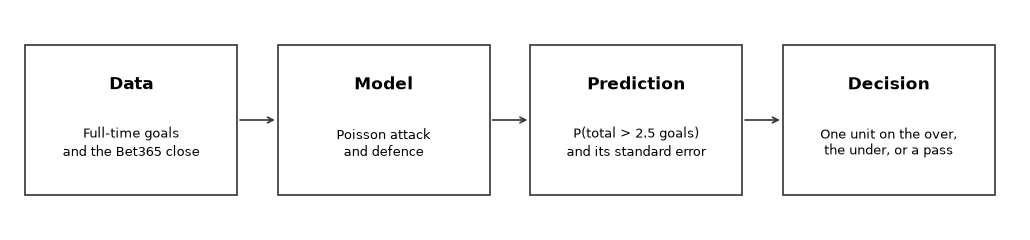

In [2]:
fig, ax = plt.subplots(figsize=(10.4, 2.5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
layers = [
    (0.015, "Data", "Full-time goals\nand the Bet365 close"),
    (0.265, "Model", "Poisson attack\nand defence"),
    (0.515, "Prediction", "P(total > 2.5 goals)\nand its standard error"),
    (0.765, "Decision", "One unit on the over,\nthe under, or a pass"),
]
for x, title, body in layers:
    ax.add_patch(
        plt.Rectangle((x, 0.16), 0.21, 0.68, fill=False, linewidth=1.2, edgecolor="#333333")
    )
    ax.text(x + 0.105, 0.66, title, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x + 0.105, 0.40, body, ha="center", va="center", fontsize=9, linespacing=1.35)
for x in (0.225, 0.475, 0.725):
    ax.annotate(
        "",
        xy=(x + 0.04, 0.50),
        xytext=(x, 0.50),
        arrowprops={"arrowstyle": "->", "color": "#333333", "lw": 1.2},
    )
fig.tight_layout()
fig.savefig(FIG_DIR / "layers.png", dpi=150, bbox_inches="tight")
plt.show()


## Data

The six files are downloaded with the command in `data/README.md`. They are not on a GitHub release: the Football-Data disclaimer does not grant a licence to republish the CSVs. The notebook reads the local copies from `data/` after the hash check above.

The source is Football-Data.co.uk, one `E0` file per Premier League season, compiled from public results and from bookmaker prices. The unit of observation is one completed match: 2,280 matches from 9 August 2019 through 25 May 2025, of which 2,279 have a usable Bet365 close.

The file records the score after the whistle. The stake needs \(P(Q > 2.5)\) before kickoff, and `B365C>2.5` and `B365C<2.5` are decimal prices, not that probability. Shots, cards, and the other in-match columns are recorded during the match, so they stay out of the forecast. The gap on the score is that the file has \(Q\) and the decision needs a probability for \(Q\). The gap on the price is the overround: the two implied probabilities sum to more than 1. That is a margin on the book, not noise in the goal count.

The plot and the table are computed from these 2,279 matches, before any model. The plot is saved as `fig/total_goals.png`.


,Matches,First match,Last match,Mean home goals,Mean away goals,Mean total goals,SD of total goals,Share over 2.5,Mean closing over price,Mean closing under price,Mean overround
2019/20,380,2019-08-09,2020-07-26,1.516,1.205,2.721,1.512,0.521,1.812,2.164,1.055
2020/21,380,2020-09-12,2021-05-23,1.353,1.342,2.695,1.756,0.500,1.864,2.045,1.054
2021/22,379,2021-08-13,2022-05-22,1.517,1.298,2.815,1.627,0.538,1.875,2.051,1.050
2022/23,380,2022-08-05,2023-05-28,1.634,1.218,2.853,1.791,0.526,1.842,2.103,1.045
2023/24,380,2023-08-11,2024-05-19,1.800,1.479,3.279,1.657,0.647,1.660,2.416,1.052
2024/25,380,2024-08-16,2025-05-25,1.513,1.421,2.934,1.617,0.566,1.660,2.393,1.048
All,2279,2019-08-09,2025-05-25,1.556,1.327,2.883,1.672,0.550,1.785,2.195,1.051


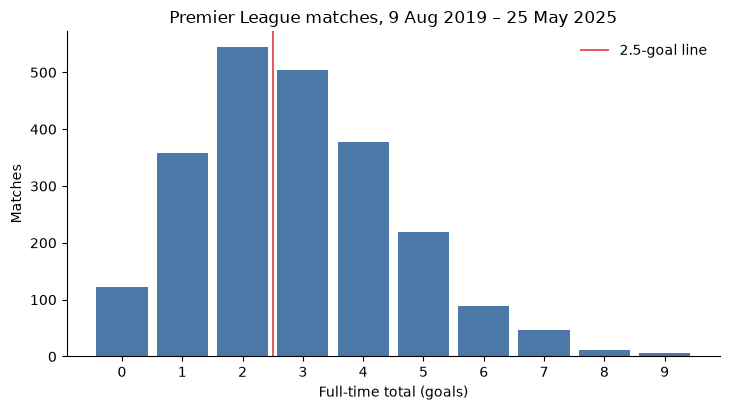

2279 matches, 2019-08-09 through 2025-05-25. Mean total 2.88 goals (SD 1.67). 55.0% finish over 2.5. Mean overround 1.051: the two closing prices sum to more than a fair book.


In [3]:
def season_summary(frame):
    overround = 1.0 / frame["o_over"] + 1.0 / frame["o_under"]
    return {
        "Matches": int(len(frame)),
        "First match": frame["date"].min().strftime("%Y-%m-%d"),
        "Last match": frame["date"].max().strftime("%Y-%m-%d"),
        "Mean home goals": frame["home_goals"].mean(),
        "Mean away goals": frame["away_goals"].mean(),
        "Mean total goals": frame["total_goals"].mean(),
        "SD of total goals": frame["total_goals"].std(ddof=1),
        "Share over 2.5": frame["over"].mean(),
        "Mean closing over price": frame["o_over"].mean(),
        "Mean closing under price": frame["o_under"].mean(),
        "Mean overround": overround.mean(),
    }

summary = pd.DataFrame(
    {label: season_summary(frame) for label, frame in matches.groupby("season", sort=False)}
).T
summary.loc["All"] = pd.Series(season_summary(matches))
summary["Matches"] = summary["Matches"].astype(int)
number_cols = [col for col in summary.columns if col not in ("Matches", "First match", "Last match")]
shown = summary.copy()
shown[number_cols] = shown[number_cols].astype(float).round(3)
display(shown)

counts = matches["total_goals"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.bar(counts.index, counts.to_numpy(), width=0.85, color="#4C78A8")
ax.axvline(2.5, color="#E45756", linewidth=1.4, label="2.5-goal line")
ax.set_xlabel("Full-time total (goals)")
ax.set_ylabel("Matches")
ax.set_title("Premier League matches, 9 Aug 2019 – 25 May 2025")
ax.set_xticks(range(0, int(counts.index.max()) + 1))
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "total_goals.png", dpi=150)
plt.show()

overall = summary.loc["All"]
print(
    f"{int(overall['Matches'])} matches, {overall['First match']} through {overall['Last match']}. "
    f"Mean total {overall['Mean total goals']:.2f} goals "
    f"(SD {overall['SD of total goals']:.2f}). "
    f"{overall['Share over 2.5']:.1%} finish over 2.5. "
    f"Mean overround {overall['Mean overround']:.3f}: the two closing prices sum to more than a fair book."
)


## Split

The holdout is every match after 19 May 2024, the last match of 2023/24. That is the 2024/25 season. Training is 9 August 2019 through 19 May 2024. The cutoff is the 2026-11-18 split entry in `decisions.md`. It is a date, not a random fraction, so there is no seed.

Club strengths are estimated on the training matches only. A 2024/25 result is not used to forecast a later 2024/25 match. Prices on the holdout enter the stake rule and the score. They are not covariates in the fit.


In [4]:
train = matches.loc[matches["date"] <= CUTOFF].copy()
holdout = matches.loc[matches["date"] > CUTOFF].copy()

if train["date"].max() != CUTOFF or train["date"].min() != pd.Timestamp("2019-08-09"):
    raise RuntimeError("Training window is not 9 August 2019 through 19 May 2024.")
if holdout["date"].min() != pd.Timestamp("2024-08-16") or holdout["date"].max() != pd.Timestamp("2025-05-25"):
    raise RuntimeError("Holdout is not 16 August 2024 through 25 May 2025.")
if len(train) != 1899 or len(holdout) != 380:
    raise RuntimeError(f"Expected 1899 training and 380 holdout matches. Got {len(train)} and {len(holdout)}.")
if set(holdout["season"]) != {"2024/25"}:
    raise RuntimeError("Holdout contains a season other than 2024/25.")

train_clubs = set(train["HomeTeam"]) | set(train["AwayTeam"])
holdout_clubs = set(holdout["HomeTeam"]) | set(holdout["AwayTeam"])
unseen = sorted(holdout_clubs - train_clubs)

split_table = pd.DataFrame(
    [
        {
            "Part": "Training",
            "Matches": len(train),
            "First match": train["date"].min().strftime("%Y-%m-%d"),
            "Last match": train["date"].max().strftime("%Y-%m-%d"),
            "Share over 2.5": train["over"].mean(),
        },
        {
            "Part": "Holdout",
            "Matches": len(holdout),
            "First match": holdout["date"].min().strftime("%Y-%m-%d"),
            "Last match": holdout["date"].max().strftime("%Y-%m-%d"),
            "Share over 2.5": holdout["over"].mean(),
        },
    ]
)
shown_split = split_table.copy()
shown_split["Share over 2.5"] = shown_split["Share over 2.5"].round(3)
display(shown_split)
print(
    "The holdout share is the outcome on 2024/25. It is not a feature and it is not the baseline probability."
)
print(
    "Clubs in the holdout with no training match, scored as an average club: "
    + (", ".join(unseen) if unseen else "none")
    + "."
)


,Part,Matches,First match,Last match,Share over 2.5
0,Training,1899,2019-08-09,2024-05-19,0.547
1,Holdout,380,2024-08-16,2025-05-25,0.566


The holdout share is the outcome on 2024/25. It is not a feature and it is not the baseline probability.
Clubs in the holdout with no training match, scored as an average club: Ipswich.


## Baseline

The baseline probability is the share of training matches with a total over 2.5. Every holdout match gets that same probability. It is the mean of the outcome the stake cares about.

The stake is the same rule as the model: over when \(p > 1/o_{\text{over}}\), under when \(1 - p > 1/o_{\text{under}}\), otherwise pass. If both inequalities hold, the stake is a pass. With an overround above 1 they do not both hold. The score is the mean profit per holdout match, in stake units. A pass scores 0.


In [5]:
def stake_profit(probability, frame):
    """Profit of one unit under the 2026-10-29 rule. A pass is 0."""
    probability = np.asarray(probability, dtype=float)
    o_over = frame["o_over"].to_numpy(dtype=float)
    o_under = frame["o_under"].to_numpy(dtype=float)
    over = frame["over"].to_numpy(dtype=bool)
    clear_over = probability > (1.0 / o_over)
    clear_under = (1.0 - probability) > (1.0 / o_under)
    both = clear_over & clear_under
    take_over = clear_over & ~both
    take_under = clear_under & ~both
    profit = np.zeros(len(frame), dtype=float)
    profit[take_over] = np.where(over[take_over], o_over[take_over] - 1.0, -1.0)
    profit[take_under] = np.where(~over[take_under], o_under[take_under] - 1.0, -1.0)
    return profit, take_over, take_under, both


def profit_summary(name, profit, take_over, take_under, both):
    mean = float(np.mean(profit))
    se = float(np.std(profit, ddof=1) / np.sqrt(len(profit)))
    return {
        "Rule": name,
        "Mean profit per match": mean,
        "Standard error": se,
        "Over stakes": int(take_over.sum()),
        "Under stakes": int(take_under.sum()),
        "Passes": int(len(profit) - take_over.sum() - take_under.sum() - both.sum()),
        "Both sides": int(both.sum()),
    }


p_baseline = float(train["over"].mean())
profit_baseline, over_baseline, under_baseline, both_baseline = stake_profit(
    np.full(len(holdout), p_baseline), holdout
)
baseline_row = profit_summary(
    "Training over-rate", profit_baseline, over_baseline, under_baseline, both_baseline
)
print(f"Baseline probability, from training matches only: {p_baseline:.4f}.")
display(pd.DataFrame([baseline_row]).round(4))
print(
    "Mean profit is in stake units per holdout match. "
    "The standard error treats the 380 match profits as independent."
)


Baseline probability, from training matches only: 0.5466.


,Rule,Mean profit per match,Standard error,Over stakes,Under stakes,Passes,Both sides
0,Training over-rate,0.0126,0.0555,86,201,93,0


Mean profit is in stake units per holdout match. The standard error treats the 380 match profits as independent.


## Model

Home goals and away goals are independent Poisson counts. The rates depend on the two clubs and on who is at home:

\[
\log \lambda^H = \mu + \eta + \alpha_h + \delta_a,
\qquad
\log \lambda^A = \mu + \alpha_a + \delta_h.
\]

\(Q = Y^H + Y^A\), and the probability the stake uses is

\[
p = P(Q > 2.5)
= 1 - \sum_{k=0}^{2} \sum_{j=0}^{k}
\mathrm{Poisson}(j; \lambda^H)\, \mathrm{Poisson}(k - j; \lambda^A).
\]

\(\mu\) is the log of the away-goal rate when both clubs are average. \(\eta\) is home advantage, the extra log rate for the home club. \(\alpha_c\) is the attack of club \(c\): the log change in the goals that club scores against an average defence. \(\delta_c\) is the defence of club \(c\): the log change in the goals opponents score against it. A larger \(\delta\) is a weaker defence. Attacks sum to 0 and defences sum to 0 across the training clubs, which fixes the level of \(\mu\).

The likelihood is the training goals only. The closing price is not a covariate. It enters only when the probability is turned into a stake. A club with no training match gets \(\alpha = \delta = 0\), the average club.

Assumptions. Given the rates, the two goal counts are independent, and each club's attack and defence stay constant from 9 August 2019 to 19 May 2024. The constant-strength assumption is the one trusted least. Part of 2019/20 was played behind closed doors, and a club that left the league in 2023 is not that club in 2024/25.

Uncertainty. Given the rates, the distribution of \(Q\) is the convolution of the two Poissons. The standard error on \(p\) comes from the observed information of the maximum likelihood estimate, by the delta method. That is uncertainty in the rates. It is not the sampling error of one match's result.

The held-out score uses the same stake rule and the same unit as the baseline: mean profit per match, in stake units.


In [6]:
def unpack(theta, n_clubs):
    mu = theta[0]
    eta = theta[1]
    alpha = np.zeros(n_clubs)
    delta = np.zeros(n_clubs)
    alpha[1:] = theta[2 : n_clubs + 1]
    delta[1:] = theta[n_clubs + 1 :]
    alpha[0] = -alpha[1:].sum()
    delta[0] = -delta[1:].sum()
    return mu, eta, alpha, delta


def fit_strengths(training_matches):
    clubs = sorted(set(training_matches["HomeTeam"]) | set(training_matches["AwayTeam"]))
    index = {club: i for i, club in enumerate(clubs)}
    n_clubs = len(clubs)
    home = training_matches["HomeTeam"].map(index).to_numpy()
    away = training_matches["AwayTeam"].map(index).to_numpy()
    home_goals = training_matches["home_goals"].to_numpy()
    away_goals = training_matches["away_goals"].to_numpy()

    def negative_log_likelihood(theta):
        mu, eta, alpha, delta = unpack(theta, n_clubs)
        lam_home = np.exp(mu + eta + alpha[home] + delta[away])
        lam_away = np.exp(mu + alpha[away] + delta[home])
        log_lik = np.sum(home_goals * np.log(lam_home) - lam_home - gammaln(home_goals + 1.0))
        log_lik += np.sum(away_goals * np.log(lam_away) - lam_away - gammaln(away_goals + 1.0))
        return -float(log_lik)

    # Fixed start. mu near a typical away rate; every club at the average.
    start = np.zeros(2 * n_clubs)
    start[0] = np.log(1.25)
    result = minimize(negative_log_likelihood, start, method="L-BFGS-B")
    if not result.success:
        raise RuntimeError(result.message)
    return clubs, index, result.x, result.fun, negative_log_likelihood


def lookup(series, values, index):
    mapped = series.map(index)
    out = np.zeros(len(series), dtype=float)
    known = mapped.notna().to_numpy()
    out[known] = values[mapped.loc[known].astype(int).to_numpy()]
    return out


def rates(theta, frame, index):
    mu, eta, alpha, delta = unpack(theta, len(index))
    attack_home = lookup(frame["HomeTeam"], alpha, index)
    defence_home = lookup(frame["HomeTeam"], delta, index)
    attack_away = lookup(frame["AwayTeam"], alpha, index)
    defence_away = lookup(frame["AwayTeam"], delta, index)
    lam_home = np.exp(mu + eta + attack_home + defence_away)
    lam_away = np.exp(mu + attack_away + defence_home)
    return lam_home, lam_away


def probability_over(lam_home, lam_away):
    lam_home = np.asarray(lam_home, dtype=float)
    lam_away = np.asarray(lam_away, dtype=float)
    at_most_two = np.zeros(len(lam_home), dtype=float)
    for total in range(3):
        for home_goals in range(total + 1):
            at_most_two += poisson.pmf(home_goals, lam_home) * poisson.pmf(total - home_goals, lam_away)
    return 1.0 - at_most_two


clubs, club_index, theta, training_nll, negative_log_likelihood = fit_strengths(train)
mu, eta, alpha, delta = unpack(theta, len(clubs))
print(
    f"Fitted on {len(train)} training matches and {len(clubs)} clubs. "
    f"Negative log likelihood {training_nll:.1f}."
)
print(
    f"An average club scores {np.exp(mu + eta):.2f} goals at home and {np.exp(mu):.2f} away. "
    f"Home multiplies the rate by {np.exp(eta):.3f}."
)

strength = pd.DataFrame({"Attack": alpha, "Defence": delta}, index=clubs)
strength.index.name = "Club"
display(strength.sort_values("Attack", ascending=False).round(3))

lam_home, lam_away = rates(theta, holdout, club_index)
p_model = probability_over(lam_home, lam_away)
profit_model, over_model, under_model, both_model = stake_profit(p_model, holdout)
model_row = profit_summary("Poisson strengths", profit_model, over_model, under_model, both_model)

pass_row = {
    "Rule": "Pass",
    "Mean profit per match": 0.0,
    "Standard error": 0.0,
    "Over stakes": 0,
    "Under stakes": 0,
    "Passes": len(holdout),
    "Both sides": 0,
}
scores = pd.DataFrame([pass_row, baseline_row, model_row])
display(scores.round(4))

gap = profit_model - profit_baseline
gap_mean = float(gap.mean())
gap_se = float(np.std(gap, ddof=1) / np.sqrt(len(gap)))
print(
    f"Poisson minus training over-rate: {gap_mean:.4f} stake units per match (SE {gap_se:.4f}). "
    f"Higher on {(gap > 0).mean():.1%} of matches, equal on {(gap == 0).mean():.1%}, "
    f"lower on {(gap < 0).mean():.1%}."
)
print(
    "Both scores are mean profit per holdout match, in stake units. "
    "A pass is the zero of that scale. Neither fitted rule is far from a pass "
    "relative to a standard error that treats matches as independent."
)

def observed_information(training_matches, fitted_theta, index):
    """Observed information of the Poisson log likelihood at the fitted rates.

    For a Poisson count with log rate x·θ, the contribution is λ x xᵀ.
    Club 0 is the sum-to-zero constraint, so its column is minus the other clubs.
    """
    n_clubs = len(index)
    n_free = 2 * n_clubs
    mu_hat, eta_hat, alpha_hat, delta_hat = unpack(fitted_theta, n_clubs)
    home_ix = training_matches["HomeTeam"].map(index).to_numpy()
    away_ix = training_matches["AwayTeam"].map(index).to_numpy()
    lam_h = np.exp(mu_hat + eta_hat + alpha_hat[home_ix] + delta_hat[away_ix])
    lam_a = np.exp(mu_hat + alpha_hat[away_ix] + delta_hat[home_ix])

    def design(attack_club, defence_club, home_advantage):
        design_matrix = np.zeros((len(attack_club), n_free))
        design_matrix[:, 0] = 1.0
        design_matrix[:, 1] = home_advantage
        attack_base = attack_club == 0
        design_matrix[attack_base, 2 : n_clubs + 1] = -1.0
        attack_rows = np.flatnonzero(~attack_base)
        design_matrix[attack_rows, 1 + attack_club[attack_rows]] = 1.0
        defence_base = defence_club == 0
        design_matrix[defence_base, n_clubs + 1 :] = -1.0
        defence_rows = np.flatnonzero(~defence_base)
        design_matrix[defence_rows, n_clubs + defence_club[defence_rows]] = 1.0
        return design_matrix

    home_design = design(home_ix, away_ix, 1.0)
    away_design = design(away_ix, home_ix, 0.0)
    return (home_design * lam_h[:, None]).T @ home_design + (away_design * lam_a[:, None]).T @ away_design


information = observed_information(train, theta, club_index)
smallest = float(np.linalg.eigvalsh(information).min())
if smallest <= 0:
    raise RuntimeError(f"Observed information is not positive definite (smallest eigenvalue {smallest}).")
information_inv = np.linalg.inv(information)

# Delta method. The step is numerical only; the information above is exact at the fitted rates.
step = 1e-4
sensitivity = np.zeros((len(holdout), len(theta)))
for j in range(len(theta)):
    shifted = theta.copy()
    shifted[j] += step
    shifted_home, shifted_away = rates(shifted, holdout, club_index)
    sensitivity[:, j] = (probability_over(shifted_home, shifted_away) - p_model) / step
variance = np.einsum("ij,jk,ik->i", sensitivity, information_inv, sensitivity)
p_se = np.sqrt(np.maximum(variance, 0.0))

preview = pd.DataFrame(
    {
        "Date": holdout["date"].dt.strftime("%Y-%m-%d").to_numpy(),
        "Home": holdout["HomeTeam"].to_numpy(),
        "Away": holdout["AwayTeam"].to_numpy(),
        "Home rate": lam_home,
        "Away rate": lam_away,
        "P(Q > 2.5)": p_model,
        "SE": p_se,
        "Action": np.where(over_model, "over", np.where(under_model, "under", "pass")),
        "Profit": profit_model,
    }
)
print(
    f"Standard error of p on the holdout: median {np.median(p_se):.3f}, "
    f"minimum {p_se.min():.3f}, maximum {p_se.max():.3f}."
)
print("First eight holdout matches. The score above uses all 380.")
display(preview.head(8).round(3))


Fitted on 1899 training matches and 26 clubs. Negative log likelihood 5603.9.
An average club scores 1.48 goals at home and 1.24 away. Home multiplies the rate by 1.194.


,Attack,Defence
Club,,
Man City,0.624,-0.529
Liverpool,0.483,-0.381
Arsenal,0.335,-0.301
Tottenham,0.319,-0.089
Chelsea,0.241,-0.188
Leicester,0.224,-0.033
Man United,0.220,-0.168
Newcastle,0.129,-0.028
Aston Villa,0.104,-0.034


,Rule,Mean profit per match,Standard error,Over stakes,Under stakes,Passes,Both sides
0,Pass,0.0000,0.0000,0,0,380,0
1,Training over-rate,0.0126,0.0555,86,201,93,0
2,Poisson strengths,-0.0039,0.0546,66,236,78,0


Poisson minus training over-rate: -0.0164 stake units per match (SE 0.0451). Higher on 20.3% of matches, equal on 59.7%, lower on 20.0%.
Both scores are mean profit per holdout match, in stake units. A pass is the zero of that scale. Neither fitted rule is far from a pass relative to a standard error that treats matches as independent.
Standard error of p on the holdout: median 0.042, minimum 0.027, maximum 0.059.
First eight holdout matches. The score above uses all 380.


,Date,Home,Away,Home rate,Away rate,P(Q > 2.5),SE,Action,Profit
0,2024-08-16,Man United,Fulham,1.776,0.969,0.517,0.048,under,1.30
1,2024-08-17,Ipswich,Liverpool,1.011,2.008,0.581,0.029,under,2.20
2,2024-08-17,Arsenal,Wolves,1.858,0.760,0.486,0.042,under,2.00
3,2024-08-17,Everton,Brighton,1.129,1.196,0.410,0.039,under,-1.00
4,2024-08-17,Newcastle,Southampton,1.969,1.088,0.590,0.044,under,1.75
5,2024-08-17,Nott'm Forest,Bournemouth,1.558,1.279,0.539,0.059,over,-1.00
6,2024-08-17,West Ham,Aston Villa,1.579,1.401,0.572,0.040,pass,0.00
7,2024-08-18,Brentford,Crystal Palace,1.518,1.061,0.476,0.047,pass,0.00


## Simulation check

Two draws, both from seed 20241118 in `decisions.md`. Neither draw is used to score the holdout.

The first redraws every training total from the fitted home and away rates, 400 times, and compares the redrawn totals with the real training totals.

The second builds a league of eight clubs from known attack and defence, 40 rounds of home and away, 2,240 matches. The same optimiser is started from \(\mu = \log 1.25\) and zeros, and the estimates are compared with the rates that generated the matches.


,Source,Mean total goals,SD of total goals,Share over 2.5
0,Training matches,2.873,1.683,0.547
1,Mean of 400 draws,2.876,1.740,0.543


The fitted rates reproduce the training mean and the share of totals over 2.5. The redrawn totals are a little wider (SD 1.74 against the real SD 1.68).


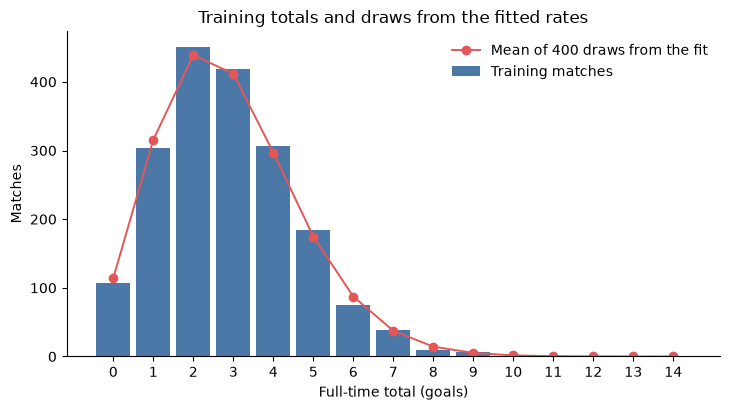

,Parameter,Truth,Estimate
0,"mu, log away rate",0.20,0.224
1,"eta, home advantage",0.15,0.124
2,"Attack, correlation",1.00,0.991
3,"Attack, RMSE",0.00,0.037
4,"Defence, correlation",1.00,0.983
5,"Defence, RMSE",0.00,0.039


On 2,240 simulated matches the fit recovers the attacks (correlation 0.991, RMSE 0.037) and the defences (correlation 0.983, RMSE 0.039). mu is off by +0.024 and eta by -0.026.


In [7]:
parent = np.random.default_rng(20241118)
replicate_rng, recovery_rng = parent.spawn(2)

train_home, train_away = rates(theta, train, club_index)
n_replicates = 400
simulated_totals = replicate_rng.poisson(
    train_home, size=(n_replicates, len(train))
) + replicate_rng.poisson(train_away, size=(n_replicates, len(train)))
real_totals = train["total_goals"].to_numpy()

replication = pd.DataFrame(
    [
        {
            "Source": "Training matches",
            "Mean total goals": real_totals.mean(),
            "SD of total goals": real_totals.std(ddof=1),
            "Share over 2.5": (real_totals > 2.5).mean(),
        },
        {
            "Source": "Mean of 400 draws",
            "Mean total goals": simulated_totals.mean(axis=1).mean(),
            "SD of total goals": simulated_totals.std(axis=1, ddof=1).mean(),
            "Share over 2.5": (simulated_totals > 2.5).mean(axis=1).mean(),
        },
    ]
)
display(replication.round(3))
print(
    "The fitted rates reproduce the training mean and the share of totals over 2.5. "
    f"The redrawn totals are a little wider "
    f"(SD {simulated_totals.std(axis=1, ddof=1).mean():.2f} against the real SD {real_totals.std(ddof=1):.2f})."
)

goal_cap = int(max(real_totals.max(), simulated_totals.max()))
goal_values = np.arange(0, goal_cap + 1)
real_counts = np.bincount(real_totals, minlength=goal_cap + 1)
simulated_counts = np.vstack(
    [np.bincount(row, minlength=goal_cap + 1) for row in simulated_totals]
).mean(axis=0)

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.bar(goal_values, real_counts, width=0.85, color="#4C78A8", label="Training matches")
ax.plot(
    goal_values,
    simulated_counts,
    color="#E45756",
    marker="o",
    linewidth=1.4,
    label="Mean of 400 draws from the fit",
)
ax.set_xlabel("Full-time total (goals)")
ax.set_ylabel("Matches")
ax.set_title("Training totals and draws from the fitted rates")
ax.set_xticks(goal_values)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "simulation_totals.png", dpi=150)
plt.show()

n_clubs_sim = 8
n_rounds = 40
true_mu = 0.20
true_eta = 0.15
true_alpha = np.linspace(-0.40, 0.40, n_clubs_sim)
true_alpha = true_alpha - true_alpha.mean()
true_delta = np.linspace(0.30, -0.30, n_clubs_sim)
true_delta = true_delta - true_delta.mean()
club_names = [f"C{i}" for i in range(n_clubs_sim)]
generated = []
for _round in range(n_rounds):
    for home_club in range(n_clubs_sim):
        for away_club in range(n_clubs_sim):
            if home_club == away_club:
                continue
            lam_h = np.exp(
                true_mu + true_eta + true_alpha[home_club] + true_delta[away_club]
            )
            lam_a = np.exp(true_mu + true_alpha[away_club] + true_delta[home_club])
            generated.append(
                (
                    club_names[home_club],
                    club_names[away_club],
                    int(recovery_rng.poisson(lam_h)),
                    int(recovery_rng.poisson(lam_a)),
                )
            )
fake = pd.DataFrame(
    generated, columns=["HomeTeam", "AwayTeam", "home_goals", "away_goals"]
)
if len(fake) != 2240:
    raise RuntimeError(f"The recovery league should have 2,240 matches, not {len(fake)}.")

recovered_clubs, _recovered_index, recovered_theta, _recovered_nll, _recovered_fn = fit_strengths(
    fake
)
if recovered_clubs != club_names:
    raise RuntimeError("Recovered clubs are not in the order the rates were built.")
hat_mu, hat_eta, hat_alpha, hat_delta = unpack(recovered_theta, n_clubs_sim)
attack_error = hat_alpha - true_alpha
defence_error = hat_delta - true_delta
attack_corr = float(np.corrcoef(hat_alpha, true_alpha)[0, 1])
defence_corr = float(np.corrcoef(hat_delta, true_delta)[0, 1])
attack_rmse = float(np.sqrt(np.mean(attack_error**2)))
defence_rmse = float(np.sqrt(np.mean(defence_error**2)))

recovery = pd.DataFrame(
    [
        {"Parameter": "mu, log away rate", "Truth": true_mu, "Estimate": hat_mu},
        {"Parameter": "eta, home advantage", "Truth": true_eta, "Estimate": hat_eta},
        {"Parameter": "Attack, correlation", "Truth": 1.0, "Estimate": attack_corr},
        {"Parameter": "Attack, RMSE", "Truth": 0.0, "Estimate": attack_rmse},
        {"Parameter": "Defence, correlation", "Truth": 1.0, "Estimate": defence_corr},
        {"Parameter": "Defence, RMSE", "Truth": 0.0, "Estimate": defence_rmse},
    ]
)
display(recovery.round(3))
print(
    f"On 2,240 simulated matches the fit recovers the attacks (correlation {attack_corr:.3f}, "
    f"RMSE {attack_rmse:.3f}) and the defences (correlation {defence_corr:.3f}, "
    f"RMSE {defence_rmse:.3f}). "
    f"mu is off by {hat_mu - true_mu:+.3f} and eta by {hat_eta - true_eta:+.3f}."
)


## Residuals and calibration

The holdout residual is the full-time total, minus the sum of the two fitted rates, divided by the square root of that sum. Under the Poisson model that denominator is the standard deviation of the total. A mean near zero, with no slope against the date, is what noise looks like. A mean that moves as the match gets further from 19 May 2024 is a bias that grows with the horizon.

Calibration puts the holdout matches into five bins of \(p\) and compares each bin's \(p\) with the share that finished over 2.5. The forecast is frozen at the cutoff, so the same comparison by month shows whether the miss grows through 2024/25.


Mean Pearson residual on the holdout: +0.039 (SD 0.97). Correlation with the predicted total: -0.12. Correlation with days since 19 May 2024: -0.03.
Outcome minus p changes by -0.030 per 100 days (SE 0.031). The forecast's miss does not grow detectably from August 2024 to May 2025.


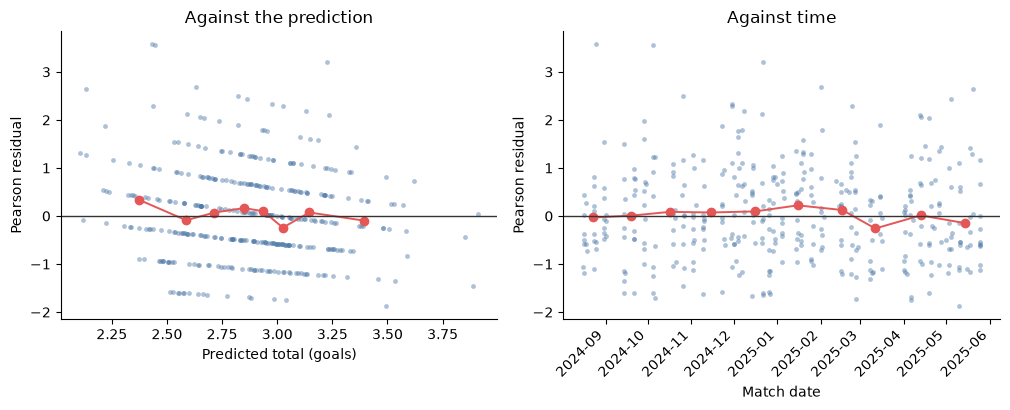

,Matches,Predicted,Observed,SE of observed,Observed minus predicted
bin,,,,,
"(0.352, 0.481]",76,0.441,0.487,0.057,0.046
"(0.481, 0.535]",76,0.507,0.539,0.057,0.032
"(0.535, 0.568]",76,0.553,0.632,0.055,0.079
"(0.568, 0.605]",76,0.585,0.513,0.057,-0.072
"(0.605, 0.748]",76,0.642,0.658,0.054,0.016


Brier score on the holdout: Poisson 0.246, training over-rate 0.246. This is a check on the probability. The decision is still scored by mean profit per match.


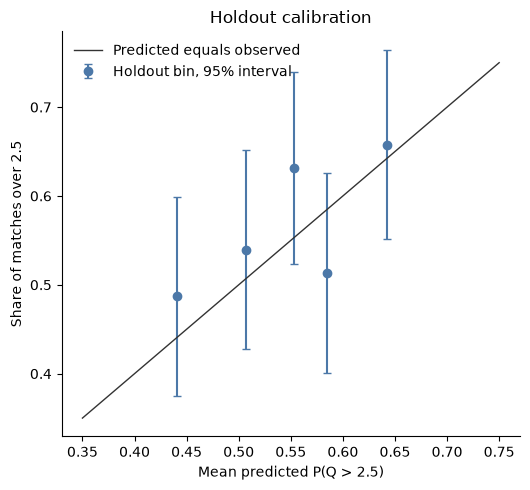

,Matches,Observed,Predicted,Mean profit per match
month,,,,
2024-08,27,0.444,0.541,0.348
2024-09,33,0.636,0.546,-0.282
2024-10,30,0.567,0.551,0.026
2024-11,36,0.583,0.540,0.055
2024-12,62,0.613,0.548,0.083
2025-01,41,0.659,0.545,-0.318
2025-02,42,0.595,0.541,0.100
2025-03,18,0.444,0.548,-0.088
2025-04,50,0.620,0.547,-0.208


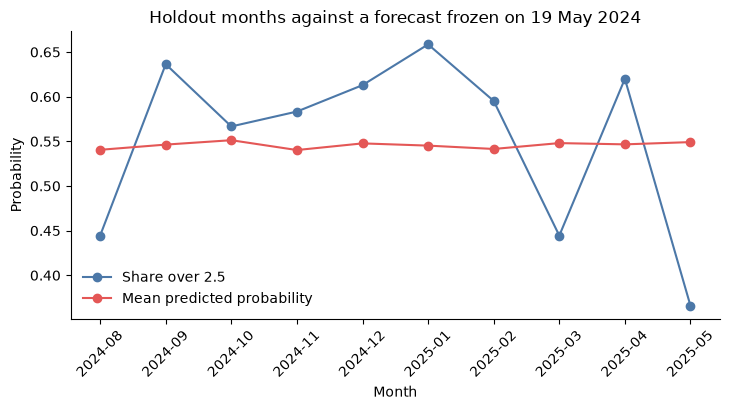

The predicted probability stays near the training over-rate in every month. The realised share moves around that line. The error from one month to the next looks like noise.


In [8]:
import matplotlib.dates as mdates
predicted_total = lam_home + lam_away
observed_total = holdout["total_goals"].to_numpy(dtype=float)
pearson = (observed_total - predicted_total) / np.sqrt(predicted_total)
days_after_cutoff = (holdout["date"] - CUTOFF).dt.days.to_numpy(dtype=float)
outcome = holdout["over"].to_numpy(dtype=float)
miss = outcome - p_model

corr_prediction = float(np.corrcoef(pearson, predicted_total)[0, 1])
corr_days = float(np.corrcoef(pearson, days_after_cutoff)[0, 1])
design = np.column_stack([np.ones(len(days_after_cutoff)), days_after_cutoff])
slope_fit, *_ = np.linalg.lstsq(design, miss, rcond=None)
miss_resid = miss - design @ slope_fit
miss_scale = np.sum(miss_resid**2) / (len(miss) - 2)
slope_se = float(np.sqrt(miss_scale * np.linalg.inv(design.T @ design)[1, 1]))

print(
    f"Mean Pearson residual on the holdout: {pearson.mean():+.3f} "
    f"(SD {pearson.std(ddof=1):.2f}). "
    f"Correlation with the predicted total: {corr_prediction:+.2f}. "
    f"Correlation with days since 19 May 2024: {corr_days:+.2f}."
)
print(
    f"Outcome minus p changes by {slope_fit[1] * 100:+.3f} per 100 days "
    f"(SE {slope_se * 100:.3f}). "
    "The forecast's miss does not grow detectably from August 2024 to May 2025."
)

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2))
axes[0].scatter(predicted_total, pearson, s=12, alpha=0.45, color="#4C78A8", linewidths=0)
bin_id = pd.qcut(predicted_total, 8, duplicates="drop")
bin_mean = pd.DataFrame({"predicted": predicted_total, "pearson": pearson, "bin": bin_id}).groupby(
    "bin", observed=True
).mean()
axes[0].plot(bin_mean["predicted"], bin_mean["pearson"], color="#E45756", marker="o", linewidth=1.4)
axes[0].axhline(0, color="#333333", linewidth=1)
axes[0].set_xlabel("Predicted total (goals)")
axes[0].set_ylabel("Pearson residual")
axes[0].set_title("Against the prediction")

axes[1].scatter(holdout["date"], pearson, s=12, alpha=0.45, color="#4C78A8", linewidths=0)
month = holdout["date"].dt.to_period("M")
month_mean = pd.DataFrame({"date": holdout["date"], "pearson": pearson, "month": month}).groupby(
    "month", observed=True
).mean()
axes[1].plot(month_mean["date"], month_mean["pearson"], color="#E45756", marker="o", linewidth=1.4)
axes[1].axhline(0, color="#333333", linewidth=1)
axes[1].set_xlabel("Match date")
axes[1].set_ylabel("Pearson residual")
axes[1].set_title("Against time")
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right")
for axis in axes:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "residuals_holdout.png", dpi=150)
plt.show()

calibration = holdout[["over"]].copy()
calibration["p"] = p_model
calibration["bin"] = pd.qcut(calibration["p"], 5, duplicates="drop")
calibration_table = calibration.groupby("bin", observed=True).agg(
    Matches=("over", "size"),
    Predicted=("p", "mean"),
    Observed=("over", "mean"),
)
calibration_table["SE of observed"] = np.sqrt(
    calibration_table["Observed"] * (1.0 - calibration_table["Observed"]) / calibration_table["Matches"]
)
calibration_table["Observed minus predicted"] = (
    calibration_table["Observed"] - calibration_table["Predicted"]
)
display(calibration_table.round(3))
brier_model = float(np.mean((p_model - outcome) ** 2))
brier_baseline = float(np.mean((p_baseline - outcome) ** 2))
print(
    f"Brier score on the holdout: Poisson {brier_model:.3f}, training over-rate {brier_baseline:.3f}. "
    "This is a check on the probability. The decision is still scored by mean profit per match."
)

fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.errorbar(
    calibration_table["Predicted"],
    calibration_table["Observed"],
    yerr=1.96 * calibration_table["SE of observed"],
    fmt="o",
    color="#4C78A8",
    capsize=3,
    label="Holdout bin, 95% interval",
)
span = np.array([0.35, 0.75])
ax.plot(span, span, color="#333333", linewidth=1, label="Predicted equals observed")
ax.set_xlabel("Mean predicted P(Q > 2.5)")
ax.set_ylabel("Share of matches over 2.5")
ax.set_title("Holdout calibration")
ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration.png", dpi=150)
plt.show()

by_month = pd.DataFrame(
    {
        "month": holdout["date"].dt.to_period("M").astype(str).to_numpy(),
        "observed": outcome,
        "predicted": p_model,
        "profit": profit_model,
    }
)
month_table = by_month.groupby("month", sort=True).agg(
    Matches=("observed", "size"),
    Observed=("observed", "mean"),
    Predicted=("predicted", "mean"),
    **{"Mean profit per match": ("profit", "mean")},
)
display(month_table.round(3))

fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.plot(month_table.index, month_table["Observed"], marker="o", color="#4C78A8", label="Share over 2.5")
ax.plot(
    month_table.index,
    month_table["Predicted"],
    marker="o",
    color="#E45756",
    label="Mean predicted probability",
)
ax.set_xlabel("Month")
ax.set_ylabel("Probability")
ax.set_title("Holdout months against a forecast frozen on 19 May 2024")
ax.tick_params(axis="x", rotation=45)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "holdout_by_month.png", dpi=150)
plt.show()
print(
    "The predicted probability stays near the training over-rate in every month. "
    "The realised share moves around that line. The error from one month to the next looks like noise."
)


## Decision

The loss is minus the mean profit per match. At probability \(p\), a unit on the over has expected profit \(p \, o_{\text{over}} - 1\), which is positive only when \(p > 1/o_{\text{over}}\). A unit on the under has expected profit \((1 - p) \, o_{\text{under}} - 1\), positive only when \(1 - p > 1/o_{\text{under}}\). A pass has expected profit 0. When \(p\) is the probability the stake is using, a stake that does not clear the price has negative expected profit, so the loss turns it down.

The cells below keep that rule. They show how many stakes flip when the club strengths or the home advantage change, what the 380 passes would have earned if a side had been forced, and what a call that already knew the winner would have collected on the same closing prices.


In [9]:
o_over = holdout["o_over"].to_numpy(dtype=float)
o_under = holdout["o_under"].to_numpy(dtype=float)
won_over = holdout["over"].to_numpy(dtype=bool)
ev_over = p_model * o_over - 1.0
ev_under = (1.0 - p_model) * o_under - 1.0
prefer_over = ev_over >= ev_under
profit_always = np.where(
    prefer_over,
    np.where(won_over, o_over - 1.0, -1.0),
    np.where(~won_over, o_under - 1.0, -1.0),
)
profit_oracle = np.where(won_over, o_over - 1.0, o_under - 1.0)
claimed = np.where(over_model, ev_over, np.where(under_model, ev_under, 0.0))
passed = ~(over_model | under_model)

def mean_se(profit):
    profit = np.asarray(profit, dtype=float)
    return float(profit.mean()), float(np.std(profit, ddof=1) / np.sqrt(len(profit)))

always_mean, always_se = mean_se(profit_always)
oracle_mean, oracle_se = mean_se(profit_oracle)
rule_table = pd.DataFrame(
    [
        {"Rule": "Pass", "Mean profit per match": 0.0, "Standard error": 0.0},
        {
            "Rule": "Clear the closing price",
            "Mean profit per match": float(profit_model.mean()),
            "Standard error": float(np.std(profit_model, ddof=1) / np.sqrt(len(profit_model))),
        },
        {
            "Rule": "Always the side with higher expected profit",
            "Mean profit per match": always_mean,
            "Standard error": always_se,
        },
        {
            "Rule": "Winner known before the stake",
            "Mean profit per match": oracle_mean,
            "Standard error": oracle_se,
        },
    ]
)
display(rule_table.round(4))
print(
    f"On the {int(passed.sum())} matches the rule passes, betting the side with the higher "
    f"model expected profit earns {profit_always[passed].mean():+.4f} per such match, "
    f"or {profit_always[passed].sum() / len(holdout):+.4f} stake units per holdout match. "
    "That is the stake the 2026-10-29 entry said to compare with a pass. "
    "It does not beat a pass by more than noise."
)
print(
    f"At its own probabilities the clearing rule expects {claimed.mean():+.3f} stake units per match. "
    f"The holdout returned {profit_model.mean():+.4f}. "
    f"A winner known in advance earns {oracle_mean:.3f}. "
    f"The gap from the Poisson rule to that call is {oracle_mean - profit_model.mean():.3f} "
    "stake units per match, which is the most a better probability could add on these prices."
)
staked = ~passed
print(
    f"The rule stakes on {int(staked.sum())} of 380 matches and loses "
    f"{(profit_model[staked] < 0).mean():.1%} of those stakes."
)

fitted_action = np.where(over_model, "over", np.where(under_model, "under", "pass"))


def adjusted_theta(strength, keep_home):
    adjusted = theta.copy()
    adjusted[2:] = adjusted[2:] * strength
    if not keep_home:
        adjusted[1] = 0.0
    return adjusted


def describe(name, probability):
    profit, take_over, take_under, both = stake_profit(probability, holdout)
    if both.any():
        raise RuntimeError(f"{name} cleared both prices on {int(both.sum())} matches.")
    action = np.where(take_over, "over", np.where(take_under, "under", "pass"))
    return {
        "Input": name,
        "Over stakes": int(take_over.sum()),
        "Under stakes": int(take_under.sum()),
        "Passes": int((~(take_over | take_under)).sum()),
        "Actions flipped": float((action != fitted_action).mean()),
        "Mean profit per match": float(profit.mean()),
    }


sensitivity_rows = [describe("Fitted strengths", p_model)]
for name, strength, keep_home in [
    ("Attacks and defences halved", 0.5, True),
    ("Every club at the average", 0.0, True),
    ("Home advantage removed", 1.0, False),
]:
    lam_h, lam_a = rates(adjusted_theta(strength, keep_home), holdout, club_index)
    sensitivity_rows.append(describe(name, probability_over(lam_h, lam_a)))
for name, probability in [
    ("p plus its standard error", np.clip(p_model + p_se, 0.0, 1.0)),
    ("p minus its standard error", np.clip(p_model - p_se, 0.0, 1.0)),
]:
    sensitivity_rows.append(describe(name, probability))

sensitivity = pd.DataFrame(sensitivity_rows)
shown_sensitivity = sensitivity.copy()
shown_sensitivity["Actions flipped"] = shown_sensitivity["Actions flipped"].round(3)
shown_sensitivity["Mean profit per match"] = shown_sensitivity["Mean profit per match"].round(4)
display(shown_sensitivity)
print(
    "The profit column is the same 380 matches scored under a changed input. "
    "It is not a search for a new rule. The differences sit inside a standard error of about 0.05."
)

low = p_model - 1.96 * p_se
high = p_model + 1.96 * p_se
threshold_over = 1.0 / o_over
threshold_under = 1.0 - 1.0 / o_under
crosses = ((low < threshold_over) & (high > threshold_over)) | (
    (low < threshold_under) & (high > threshold_under)
)
median_over = float(np.median(o_over))
median_under = float(np.median(o_under))
print(
    f"A 95% interval for p crosses a price that would change the stake on {crosses.mean():.1%} of holdout matches. "
    f"The median standard error of p is {np.median(p_se):.3f}. "
    f"At the median closing prices, {median_over:.2f} over and {median_under:.2f} under, "
    f"the rule passes only when p is between {1.0 - 1.0 / median_under:.3f} and {1.0 / median_over:.3f}."
)


,Rule,Mean profit per match,Standard error
0,Pass,0.0000,0.0000
1,Clear the closing price,-0.0039,0.0546
2,Always the side with higher expected profit,-0.0004,0.0596
3,Winner known before the stake,0.9306,0.0249


On the 78 matches the rule passes, betting the side with the higher model expected profit earns +0.0169 per such match, or +0.0035 stake units per holdout match. That is the stake the 2026-10-29 entry said to compare with a pass. It does not beat a pass by more than noise.
At its own probabilities the clearing rule expects +0.117 stake units per match. The holdout returned -0.0039. A winner known in advance earns 0.931. The gap from the Poisson rule to that call is 0.934 stake units per match, which is the most a better probability could add on these prices.
The rule stakes on 302 of 380 matches and loses 57.0% of those stakes.


,Input,Over stakes,Under stakes,Passes,Actions flipped,Mean profit per match
0,Fitted strengths,66,236,78,0.000,-0.0039
1,Attacks and defences halved,39,285,56,0.242,0.0268
2,Every club at the average,43,279,58,0.379,0.0118
3,Home advantage removed,17,330,33,0.324,0.0194
4,p plus its standard error,127,145,108,0.389,-0.0625
5,p minus its standard error,26,313,41,0.292,0.0237


The profit column is the same 380 matches scored under a changed input. It is not a search for a new rule. The differences sit inside a standard error of about 0.05.
A 95% interval for p crosses a price that would change the stake on 80.0% of holdout matches. The median standard error of p is 0.042. At the median closing prices, 1.62 over and 2.30 under, the rule passes only when p is between 0.565 and 0.617.


## Limits

An average club is fitted at 1.48 goals at home and 1.24 away, so home advantage is about a quarter of a goal. Man City's attack multiplies the goals they score by 1.87, and their defence multiplies the goals they concede by 0.59. Norwich's attack, the weakest in the training sample, multiplies scoring by 0.50. Those are the sizes of the effects the stake is using.

On the 380 holdout matches the training over-rate earns +0.0126 stake units per match and the Poisson rule earns −0.0039. The paired difference is −0.0164 with standard error 0.045. The two rules make the same profit on 59.7% of matches. A call that knew the winner would earn +0.931 on the same prices. The gap, about 0.93 stake units per match, is the most a better probability could be worth: a sure winner still only collects the closing price.

Do not trust the forecast to beat the close. This season does not separate either rule from a pass. The rule stakes on 302 of the 380 matches and loses 57% of those stakes. The model-claimed expected profit of the stakes is about +0.12 per match and the holdout returned about zero, so the fitted probabilities are sharper than the results support. A 95% interval for \(p\) crosses a price that would change the stake on about four matches in five. The median standard error of \(p\) is 0.042, and at the median prices the pass region is only about 0.05 wide.

Do not trust a club that was not in the 2023/24 season. Ipswich has no training match and is scored as an average club. Leicester and Southampton carry strengths from earlier seasons, not from the season before the holdout.

The assumption trusted least is that attack, defence, and home advantage stayed constant from 9 August 2019 through 19 May 2024, including the closed-door part of 2019/20. The summary table is the warning: 2023/24 averaged 3.28 goals and 64.7% of matches went over 2.5, against 2.88 goals and 55.0% across the whole sample. Home and away goals are also assumed independent given the clubs. The redrawn training totals match the mean and the over rate, and they are a little more spread out than the real totals.

With more time, let attack and defence change by season. Keep that change only if the holdout mean profit moves by more than the paired standard error of the difference, 0.045 stake units per match. That is the revisit line in the 2026-11-18 model entry.


In [10]:
city = clubs.index("Man City")
norwich = clubs.index("Norwich")
recent = set(train.loc[train["season"] == "2023/24", "HomeTeam"]) | set(
    train.loc[train["season"] == "2023/24", "AwayTeam"]
)
holdout_clubs = set(holdout["HomeTeam"]) | set(holdout["AwayTeam"])
missing_last_season = sorted(holdout_clubs - recent)
print(
    f"An average club scores {np.exp(mu + eta):.2f} goals at home and {np.exp(mu):.2f} away, "
    f"a difference of {np.exp(mu + eta) - np.exp(mu):.2f} goals."
)
print(
    f"Man City's attack multiplies goals scored by {np.exp(alpha[city]):.2f}, "
    f"and their defence multiplies goals conceded by {np.exp(delta[city]):.2f}. "
    f"Norwich's attack multiplies goals scored by {np.exp(alpha[norwich]):.2f}."
)
print(
    "Holdout clubs that did not play in 2023/24: " + ", ".join(missing_last_season) + "."
)
print(
    f"Holdout mean profit, stake units per match: "
    f"training over-rate {profit_baseline.mean():+.4f}, "
    f"Poisson {profit_model.mean():+.4f}, "
    f"winner known in advance {profit_oracle.mean():+.3f}."
)


An average club scores 1.48 goals at home and 1.24 away, a difference of 0.24 goals.
Man City's attack multiplies goals scored by 1.87, and their defence multiplies goals conceded by 0.59. Norwich's attack multiplies goals scored by 0.50.
Holdout clubs that did not play in 2023/24: Ipswich, Leicester, Southampton.
Holdout mean profit, stake units per match: training over-rate +0.0126, Poisson -0.0039, winner known in advance +0.931.
